# Tái hiện Waka Waka EA: fade BB/RSI + grid martingale giới hạn

Notebook dùng `engine.py` và `run_waka.py` cùng thư mục. Sửa **ô Cấu hình** rồi chọn **Run All**.

**Dữ liệu:**
- Forex `reference/data_fx/`: FXCM 1 phút bid/ask gộp thành 5m, vá ngày thiếu bằng Dukascopy.
- `reference/EURUSD5.csv`.
- Crypto `reference/data_5m/`.

**Luật mặc định**, lấy theo các trang bán lại ghi trong tài liệu:
- **Tín hiệu M15:** sell khi close > BB(20, 2) trên và RSI(14) ≥ 70; buy khi ngược lại.
- **Grid:** lệnh grid cách nhau 35 pips, tính từ lệnh đầu. Lot nhân 1.0 / 2.0 (lệnh 3–5) / 1.6 (lệnh 6+), tối đa 9 lệnh.
- **Chốt lời:** cả rổ đóng khi lời bằng 10 pips của lệnh đầu (weighted TP theo tiền).
- **Cắt lỗ:** SL 1000 pips, Max floating DD tắt.
- **Vốn:** deposit load 0,5% ở đòn bẩy 1:100.
- **Hedging:** mỗi cặp có tối đa 1 rổ buy và 1 rổ sell.

**Quy ước:**
- Cặp chéo AUDCAD/AUDNZD/NZDCAD dùng **một tài khoản chung**.
- EURUSD và crypto dùng Smart Distance: khoảng cách tỉ lệ với biến động 30 ngày, sizing có rủi ro tương đương AUDCAD.
- **Chi phí forex:** spread thật, commission 35 USD/triệu mỗi chiều, swap −1%/năm (không lấy được lãi suất từ FRED).
- **Chi phí crypto:** phí maker/taker và funding thật.
- **Stop-out:** khi equity < 50% margin.

Kết quả đầy đủ và phần walk-forward: INSIGHTS §9m.

In [29]:
# CẤU HÌNH — sửa ô này trước khi chạy
MARKET = "crosses"       # "crosses", "eurusd", "eurusd_user" (EURUSD5.csv) hoặc "crypto"
BB_WINDOW, BB_DEV = 20, 2.0
RSI_WINDOW, RSI_HIGH, RSI_LOW = 14, 70.0, 30.0
SMART = None             # None = mặc định của thị trường (chéo: 35 pips cố định; còn lại: Smart Distance)
DISTANCE_PIPS = 35.0     # khoảng cách giữa các lệnh grid (với Smart Distance: tỉ lệ so với 35)
TP_PIPS = 10.0           # lời của cả rổ = lệnh đầu x TP_PIPS
SL_PIPS = 1000.0
MAX_TRADES = 9
M2, M35, M6 = 1.0, 2.0, 1.6   # hệ số lot: lệnh 2, lệnh 3-5, lệnh 6+
DEPOSIT_LOAD = 0.005     # 0.0025 low, 0.005 medium, 0.015 high
MAX_DD = 0.3             # Max floating drawdown: 1.0 = tắt, 0.30 = đóng hết khi lỗ nổi 30% balance
BE_LEVEL = 0             # đóng hòa vốn khi rổ đủ N lệnh (0 = tắt)

In [30]:
import sys
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for parent in (Path.cwd(), *Path.cwd().parents):
    if (parent / "run_waka.py").is_file():
        sys.path.insert(0, str(parent)); break
    if (parent / "reference" / "waka" / "run_waka.py").is_file():
        sys.path.insert(0, str(parent / "reference" / "waka")); break
import run_waka as rw

core = rw.CORES[MARKET]
w = replace(core, bb_window=BB_WINDOW, bb_dev=BB_DEV, rsi_window=RSI_WINDOW, rsi_high=RSI_HIGH, rsi_low=RSI_LOW,
            smart=core.smart if SMART is None else SMART, distance_pips=DISTANCE_PIPS, tp_pips=TP_PIPS,
            sl_pips=SL_PIPS, max_trades=MAX_TRADES, m2=M2, m35=M35, m6=M6, deposit_load=DEPOSIT_LOAD,
            max_dd=MAX_DD, be_level=BE_LEVEL)
print(w)

Waka(bb_window=20, bb_dev=2.0, rsi_window=14, rsi_high=70.0, rsi_low=30.0, smart=False, distance_pips=35.0, tp_pips=10.0, sl_pips=1000.0, max_trades=9, m2=1.0, m35=2.0, m6=1.6, deposit_load=0.005, max_dd=0.3, pause_hours=24.0, be_level=0, rollover_filter=True, reverse=False, path_mode=0, touch=False)


In [31]:
if MARKET == "crypto":
    raw = {s: rw.rg.load_coin(s) for s in rw.crypto_symbols()}
    coins = {s: rw.crypto_market(c) for s, c in raw.items()}
    res = rw.run_crypto(coins, w)
    display(pd.Series(rw.evaluate_crypto(res, rw.rg.market_returns(raw))).to_frame("chiến thuật").round(3))
    equity = (1 + res["portfolio"]).cumprod()
    daily = pd.DataFrame({"equity": equity, "balance": np.nan, "min_equity": equity})
    baskets = res["baskets"]
    display(res["stats"].sort_values("total_return")[["total_return", "equity_max_dd", "basket_win_rate",
                                                       "stop_outs"]].head(10).round(3))
else:
    m = rw.load_eurusd_user() if MARKET == "eurusd_user" else rw.load_fx(rw.CROSSES if MARKET == "crosses" else ["EURUSD"], MARKET)
    res = rw.run(m, w)
    daily, baskets = res["daily"], res["baskets"]
    display(pd.Series(rw.evaluate_fx(m, res)).to_frame("chiến thuật").round(3))
    display(baskets.groupby("symbol")["pnl"].agg(["count", "sum", "mean"]).round(4))
r = daily["equity"].pct_change().dropna()
display(r.groupby(r.index.year).apply(lambda x: (1 + x).prod() - 1).rename("lợi nhuận năm").to_frame().round(3))
display(baskets["reason"].value_counts().to_frame("lý do đóng rổ"))

,chiến thuật
sharpe,0.935
sortino,0.886
cagr_at_20vol,0.182
max_dd_at_20vol,-0.302
raw_ann_return,0.254
raw_ann_vol,0.272
calmar_at_20vol,0.604
alpha_ann,0.255
alpha_t_nw,3.553
beta,-0.181


,count,sum,mean
symbol,,,
AUDCAD,2219,2.1778,0.0010
AUDNZD,1658,1.0957,0.0007
NZDCAD,2119,2.4071,0.0011


,lợi nhuận năm
2018,-0.108
2019,-0.064
2020,0.397
2021,0.203
2022,0.533
2023,0.439
2024,0.316
2025,0.354
2026,0.213


,lý do đóng rổ
reason,
take profit,5990
max drawdown,4
end of data,2


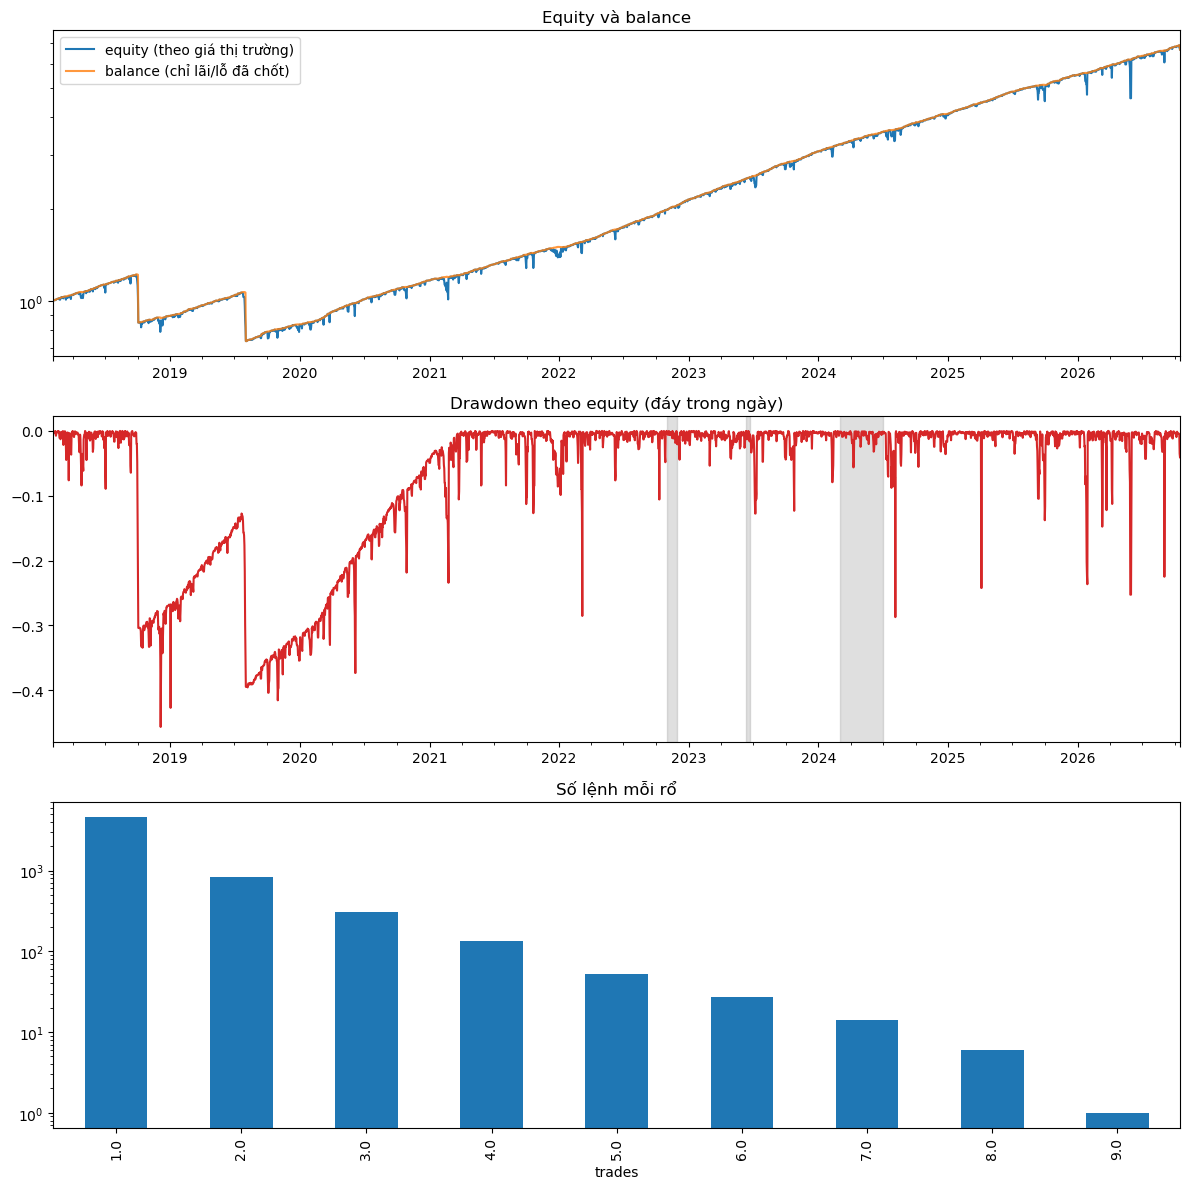

,worst_dd_in_window,month,rank_among_months,months
2022-11 AUDCAD,-0.020375,2022-11,85,105
2023-06 AUDCAD,-0.016122,2023-06,91,105
2024-03..06 AUDNZD/NZDCAD,-0.056217,2024-04,59,105


In [32]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
daily["equity"].plot(ax=axes[0], label="equity (theo giá thị trường)")
if daily["balance"].notna().any():
    daily["balance"].plot(ax=axes[0], label="balance (chỉ lãi/lỗ đã chốt)", alpha=0.8)
axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("Equity và balance")
dd = daily["min_equity"] / daily["equity"].cummax() - 1
dd.plot(ax=axes[1], color="tab:red"); axes[1].set_title("Drawdown theo equity (đáy trong ngày)")
for a, b in rw.EPISODES.values():
    axes[1].axvspan(pd.Timestamp(a), pd.Timestamp(b), color="grey", alpha=0.25)
baskets["trades"].value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set_yscale("log"); axes[2].set_title("Số lệnh mỗi rổ")
plt.tight_layout(); plt.show()
if MARKET == "crosses":
    display(rw.episodes(daily).round(3))

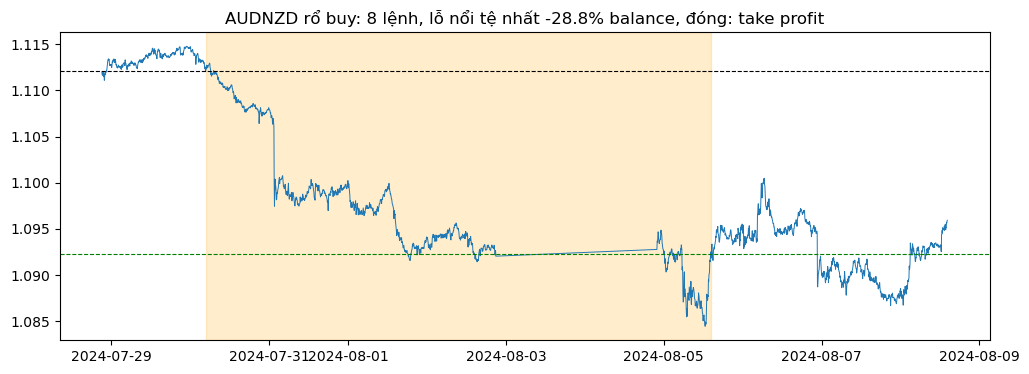

In [33]:
# Rổ sâu nhất (lỗ nổi lớn nhất) vẽ trên giá
if MARKET != "crypto":
    deep = baskets.loc[baskets["worst"].idxmin()]
    s = m.symbols.index(deep["symbol"])
    stamps = pd.to_datetime(m.ts)
    a = deep["opened"] - pd.Timedelta(days=3); b = deep["closed"] + pd.Timedelta(days=3)
    sel = (stamps >= a) & (stamps <= b)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(stamps[sel], m.bc[s, sel], lw=0.7)
    ax.axvspan(deep["opened"], deep["closed"], color="orange", alpha=0.2)
    ax.axhline(deep["entry"], color="k", ls="--", lw=0.8); ax.axhline(deep["exit"], color="g", ls="--", lw=0.8)
    ax.set_title(f"{deep['symbol']} rổ {'buy' if deep['dir'] > 0 else 'sell'}: {int(deep['trades'])} lệnh, "
                 f"lỗ nổi tệ nhất {deep['worst']:.1%} balance, đóng: {deep['reason']}")
    plt.show()

## Tổng hợp mọi thị trường

Đọc từ `reference/results/waka/`, là kết quả của `run_waka.py`. Không phụ thuộc ô Cấu hình.

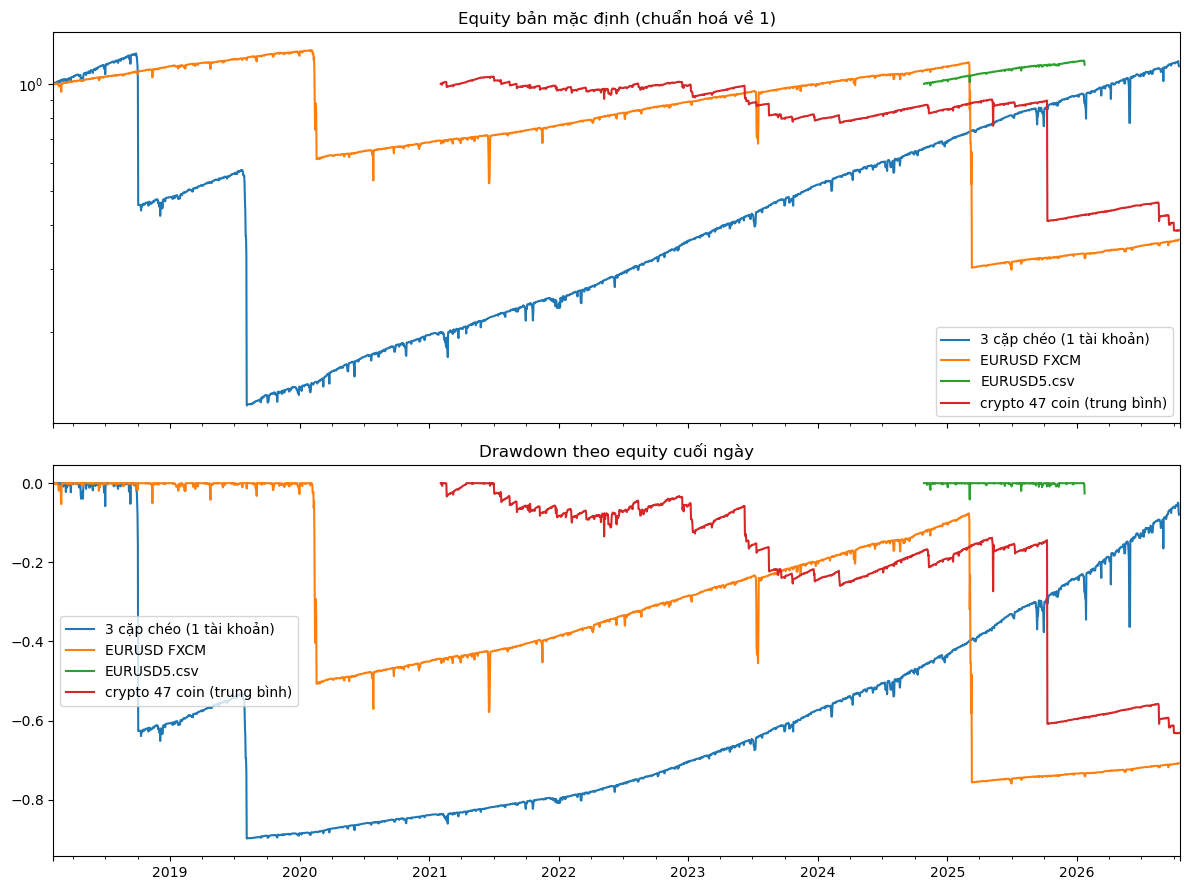

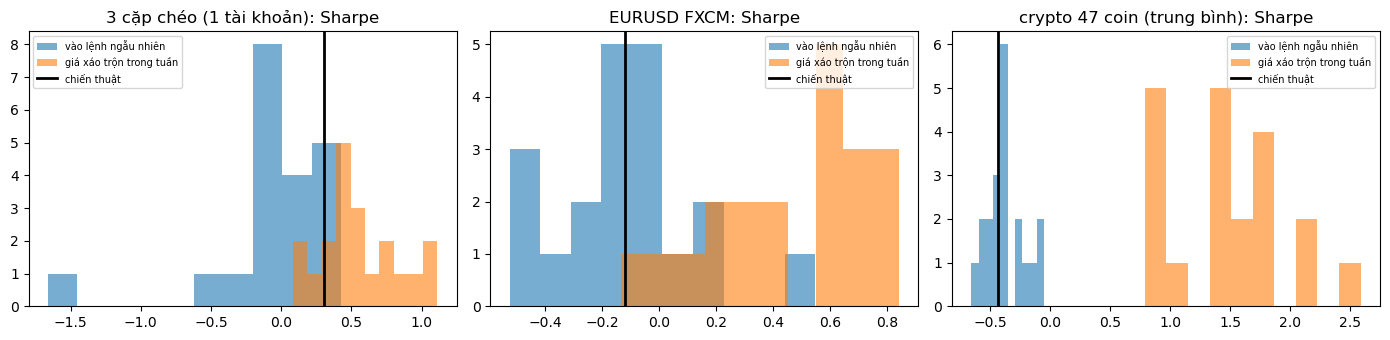

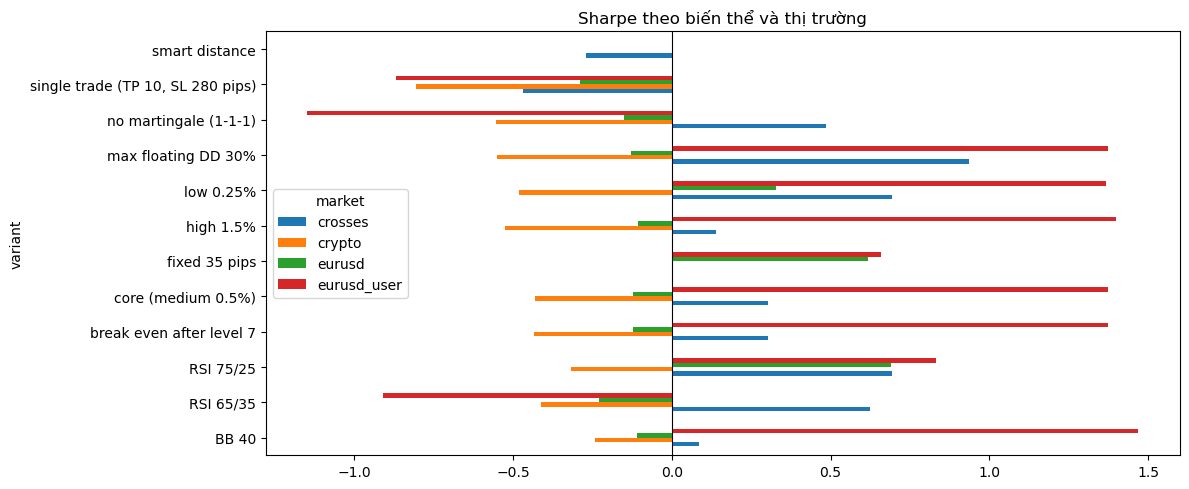

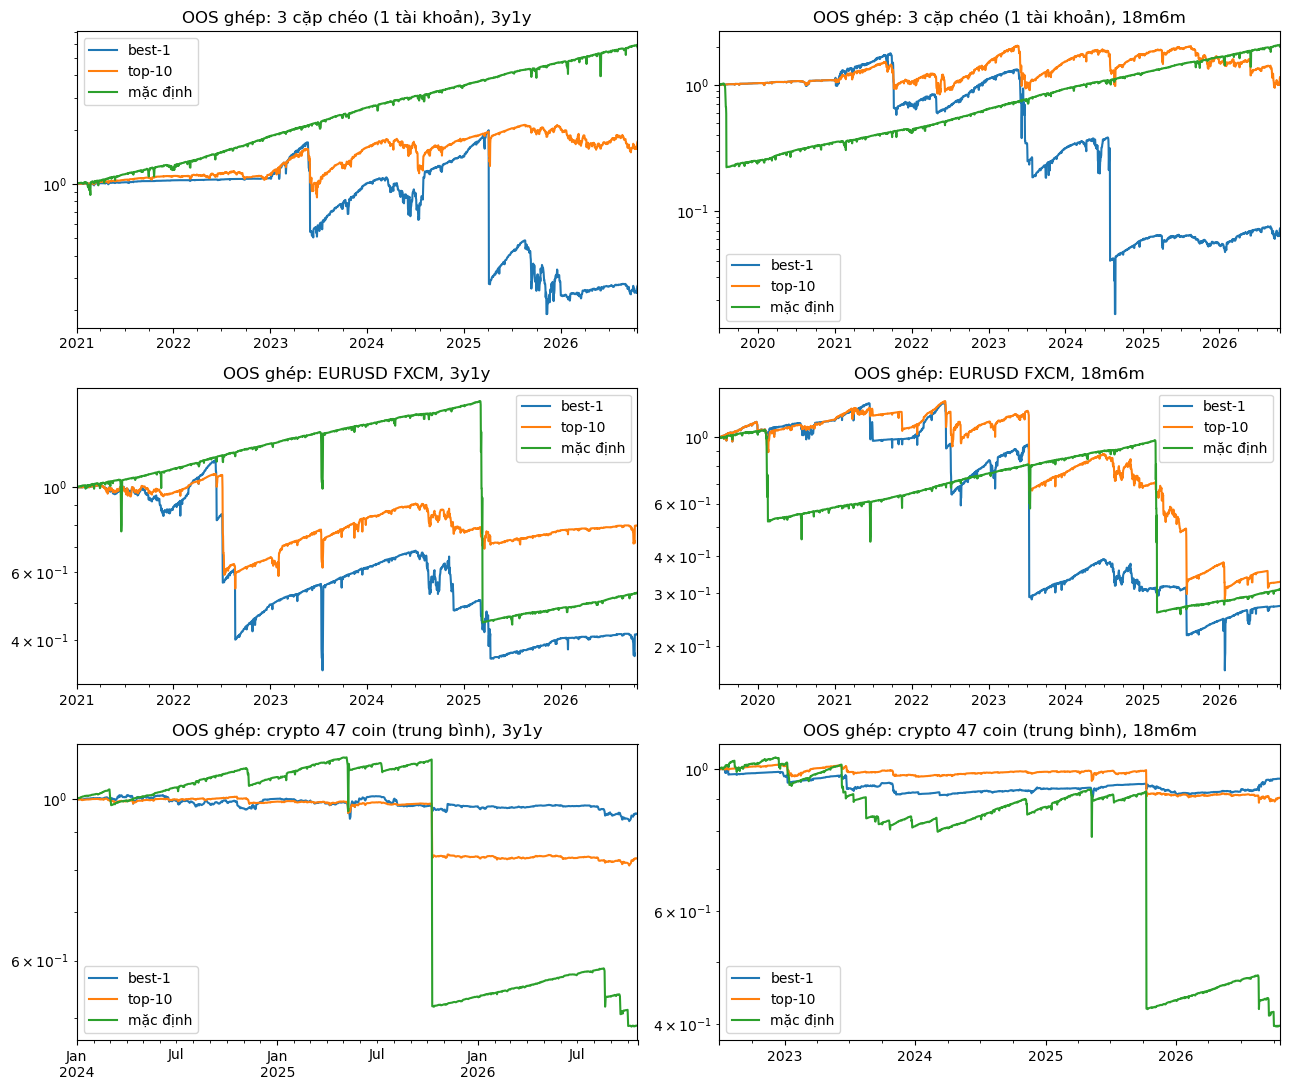

In [34]:
RES = Path(rw.OUT)
eqs = pd.read_csv(RES / "daily_equity.csv", index_col=0, parse_dates=True)
names = {"crosses": "3 cặp chéo (1 tài khoản)", "eurusd": "EURUSD FXCM", "eurusd_user": "EURUSD5.csv",
         "crypto": "crypto 47 coin (trung bình)"}
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for col in eqs.columns:
    e = eqs[col].dropna()
    (e / e.iloc[0]).plot(ax=axes[0], label=names.get(col, col))
    (e / e.cummax() - 1).plot(ax=axes[1], label=names.get(col, col))
axes[0].set_yscale("log"); axes[0].legend(); axes[0].set_title("Equity bản mặc định (chuẩn hoá về 1)")
axes[1].set_title("Drawdown theo equity cuối ngày"); axes[1].legend()
plt.tight_layout(); plt.show()

nulls = pd.read_csv(RES / "null.csv")
crit = pd.read_csv(RES / "criteria.csv").set_index("market")
fig, axes = plt.subplots(1, len(crit), figsize=(14, 3.5))
for ax, (market, row) in zip(axes, crit.iterrows()):
    n = nulls[nulls["market"] == market]
    ax.hist(n["random_entry"], bins=10, alpha=0.6, label="vào lệnh ngẫu nhiên")
    ax.hist(n["shuffled"], bins=10, alpha=0.6, label="giá xáo trộn trong tuần")
    ax.axvline(row["sharpe"], color="k", lw=2, label="chiến thuật")
    ax.set_title(f"{names.get(market, market)}: Sharpe"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

metrics_table = pd.read_csv(RES / "metrics.csv")
fig, ax = plt.subplots(figsize=(12, 5))
pivot = metrics_table.pivot(index="variant", columns="market", values="sharpe")
pivot.plot.barh(ax=ax); ax.axvline(0, color="k", lw=0.8); ax.set_title("Sharpe theo biến thể và thị trường")
plt.tight_layout(); plt.show()

OPT = RES / "opt"
fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for i, market in enumerate(["crosses", "eurusd", "crypto"]):
    for j, schedule in enumerate(["3y1y", "18m6m"]):
        path = OPT / f"oos_{market}_{schedule}.csv"
        if path.is_file():
            curves = pd.read_csv(path, index_col=0, parse_dates=True)
            curves.rename(columns={"best1": "best-1", "top10": "top-10", "core": "mặc định"}).plot(ax=axes[i, j], logy=True)
            axes[i, j].set_title(f"OOS ghép: {names.get(market, market)}, {schedule}")
plt.tight_layout(); plt.show()

## Tối ưu tham số walk-forward

Bảng và đường equity ngoài mẫu (OOS) đọc từ `reference/results/waka/opt/`, là kết quả của `optimize_waka.py`.

Grid tham số:
- forex: 15.552 bộ;
- crypto: 576 bộ.

Cách chấm:
- Trong train, chọn theo điểm lợi nhuận năm ÷ max DD theo equity.
- Đường OOS ghép các cửa sổ test của best-1, của top-10 chia đều, và của bản mặc định.

market                                     crypto             crosses  \
schedule                                     3y1y     18m6m      3y1y   
windows                                         3         9         6   
1 top10 test > 0 in >= 2/3 windows          False     False      True   
2 top10 OOS sharpe >= 0.5 and DD <= 30%     False     False     False   
3 top10 OOS ann/DD > core                    True      True     False   
best1_total                             -0.045276 -0.033386 -0.729131   
best1_ann                               -0.016406 -0.007859 -0.201931   
best1_max_dd                            -0.118928  -0.15697 -0.921539   
best1_ann_over_dd                       -0.137953 -0.050064 -0.219124   
best1_sharpe                             -0.27272 -0.158637  0.183652   
top10_total                             -0.171476 -0.097448  0.708762   
top10_ann                               -0.064957 -0.023541   0.09694   
top10_max_dd                            -0.226614 -0.211407  -0.48178   
top10_ann_over_dd                       -0.286639 -0.111353  0.201212   
top10_sharpe                            -0.620486 -0.401554  0.438271   
core_total                              -0.511499 -0.601984  4.725539   
core_ann                                -0.225693 -0.192695  0.351671   
core_max_dd                             -0.574951 -0.621348 -0.285426   
core_ann_over_dd                        -0.392543 -0.310123  1.232091   
core_sharpe                             -0.438621 -0.494534   1.20232   

market                                               eurusd            
schedule                                    18m6m      3y1y     18m6m  
windows                                        15         6        15  
1 top10 test > 0 in >= 2/3 windows          False     False     False  
2 top10 OOS sharpe >= 0.5 and DD <= 30%     False     False     False  
3 top10 OOS ann/DD > core                   False      True      True  
best1_total                             -0.927072 -0.586025 -0.727969  
best1_ann                               -0.301519 -0.141276 -0.163411  
best1_max_dd                            -0.991851 -0.825839 -0.885389  
best1_ann_over_dd                       -0.303996  -0.17107 -0.184564  
best1_sharpe                             0.139162 -0.250668 -0.241349  
top10_total                              0.150216 -0.203673 -0.672128  
top10_ann                                0.019366 -0.038567 -0.141728  
top10_max_dd                            -0.589383 -0.545514 -0.787649  
top10_ann_over_dd                        0.032858 -0.070698 -0.179937  
top10_sharpe                             0.255002 -0.058451  -0.38576  
core_total                               1.011517 -0.467738  -0.69026  
core_ann                                 0.100523 -0.103184 -0.148393  
core_max_dd                              -0.79046 -0.749666 -0.768776  
core_ann_over_dd                         0.127171  -0.13764 -0.193026  
core_sharpe                              0.500286 -0.062233 -0.194918

,window,eligible_sets,best1_test_ret,top10_test_ret,top25_test_ret_median,grid_test_ret_median,grid_share_profitable,core_test_ret,spearman_train_test
0,2021,11997,0.047,0.107,0.108,0.199,0.858,0.203,-0.027
1,2022,13208,0.026,0.013,0.059,0.032,0.562,0.533,0.081
2,2023,12859,-0.063,0.305,0.164,0.268,0.870,0.439,-0.333
3,2024,13233,0.409,0.089,0.150,0.135,0.791,0.316,0.073
4,2025,13150,-0.831,-0.002,0.038,0.050,0.605,0.354,-0.105
5,2026,13477,0.129,-0.157,-0.173,-0.111,0.349,0.212,-0.042


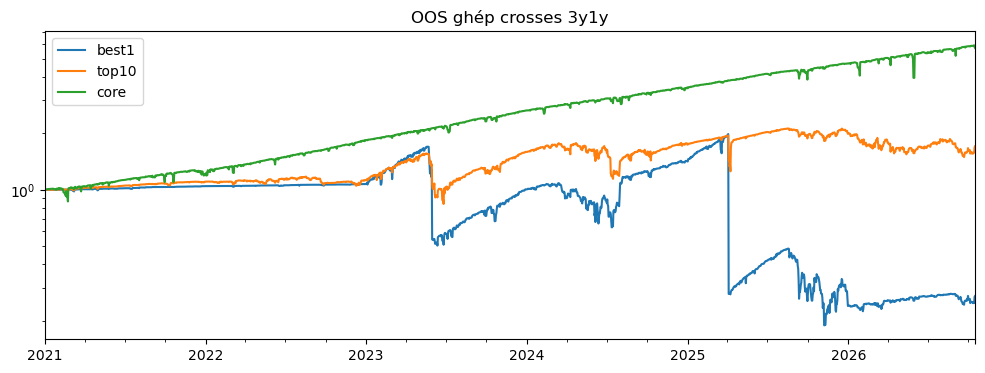

,window,eligible_sets,best1_test_ret,top10_test_ret,top25_test_ret_median,grid_test_ret_median,grid_share_profitable,core_test_ret,spearman_train_test
0,2019-H2,12474,0.031,0.032,0.018,-0.014,0.450,-0.748,0.310
1,2020-H1,12543,0.038,0.038,0.041,0.021,0.570,0.212,0.112
2,2020-H2,13448,0.011,0.011,0.030,0.017,0.604,0.152,0.158
3,2021-H1,13410,0.424,0.274,0.110,0.133,0.885,0.130,-0.094
4,2021-H2,13810,-0.552,-0.208,0.085,0.065,0.850,0.065,0.102
5,2022-H1,14729,-0.012,-0.111,0.037,0.005,0.503,0.249,0.218
6,2022-H2,14503,0.632,0.556,0.080,0.057,0.669,0.227,0.135
7,2023-H1,13686,-0.689,-0.283,0.058,0.088,0.745,0.185,-0.259
8,2023-H2,13377,-0.087,0.428,0.145,0.194,0.937,0.214,-0.269
9,2024-H1,13798,0.164,0.202,0.079,0.053,0.837,0.158,0.187


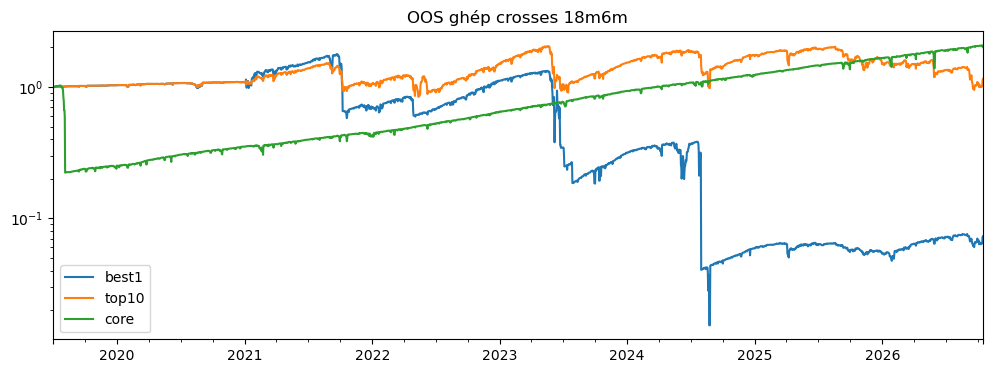

In [35]:
OPT = Path(rw.OUT) / "opt"
opt_market = MARKET if MARKET != "eurusd_user" else "eurusd"
crit = pd.read_csv(OPT / "criteria_opt.csv") if (OPT / "criteria_opt.csv").is_file() else None
if crit is not None:
    display(crit.set_index(["market", "schedule"]).T)
for schedule in ("3y1y", "18m6m"):
    path = OPT / f"wf_{opt_market}_{schedule}.csv"
    if not path.is_file():
        continue
    wf = pd.read_csv(path)
    display(wf[["window", "eligible_sets", "best1_test_ret", "top10_test_ret", "top25_test_ret_median",
                "grid_test_ret_median", "grid_share_profitable", "core_test_ret", "spearman_train_test"]].round(3))
    curves = pd.read_csv(OPT / f"oos_{opt_market}_{schedule}.csv", index_col=0, parse_dates=True)
    ax = curves.plot(figsize=(12, 4), logy=True, title=f"OOS ghép {opt_market} {schedule}")
    plt.show()